In [13]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [14]:
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt
import colormaps as cmaps
import jax.numpy as jnp
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
from utils.cosmetics import SET1_LIST

In [15]:
import time
from dataclasses import replace
import EI.ei_cavity as cv
import EI.ei_ibz as ibz
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

md = cfg["model"]
eq = cfg["equilibrium"]
sc = cfg["scan"]
op = cfg["open_system"]
nk = md["nk"]
bp = md["band"]["pars"]
taeV = 0.1
bd = eu.tb_2d(nk["scan"], **bp)
p = eu.MFPars(**md["mean_field"])

s0 = eu.solve_eq(bd, p, **eq["initial"], **eq["solve"])
d0, m0 = max(abs(float(s0.d)), 1.0e-12), float(s0.m)
tc = float(eu.critical_temperature(bd, p, **eq["critical"]))
t1, t2 = 0.2 * tc, 0.2 * tc  # photon, phonon

logger.info(f"Delta_0 = {d0} = {d0 *taeV/(8.617 * 1e-5)} K")
logger.info(f"m = {m0}")
logger.info(f"T_c = {tc} = {tc *taeV /(8.617 * 1e-5)} K")

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

[18:53:03] [INFO    ] Delta_0 = 0.08412901085102906 = 97.63143884301851 K
[18:53:03] [INFO    ] m = -0.9956695984741043
[18:53:03] [INFO    ] T_c = 0.04899871819413812 = 56.862850405173624 K


In [16]:
import numpy as np
from scipy.special import ellipkm1
from scipy.optimize import brentq

def e_bind(V, ta=1.0, tb=-1.0):
    """E_B from 2 (ta - tb) / V = 2 / (pi z) K(2 / z), z = 2 + E_B / (2 (ta - tb)).

    Depends only on V and ta - tb: not on G, m, Delta or T.
    """
    w = 2.0 * (ta - tb)  # e-h kinetic energy = G - w s, bandwidth 4 w

    def f(lx):  # root in x = log E_B, E_B can be exponentially small
        y = np.exp(lx) / w  # z - 2
        z = 2.0 + y
        return 2.0 / (np.pi * z) * ellipkm1(y * (z + 2.0) / z**2) - w / V  # K with 1 - m = 1 - 4 / z^2 exact

    return np.exp(brentq(f, np.log(1e-300 * w), np.log(1e6 * w)))

  0%|          | 0/100 [00:00<?, ?it/s]

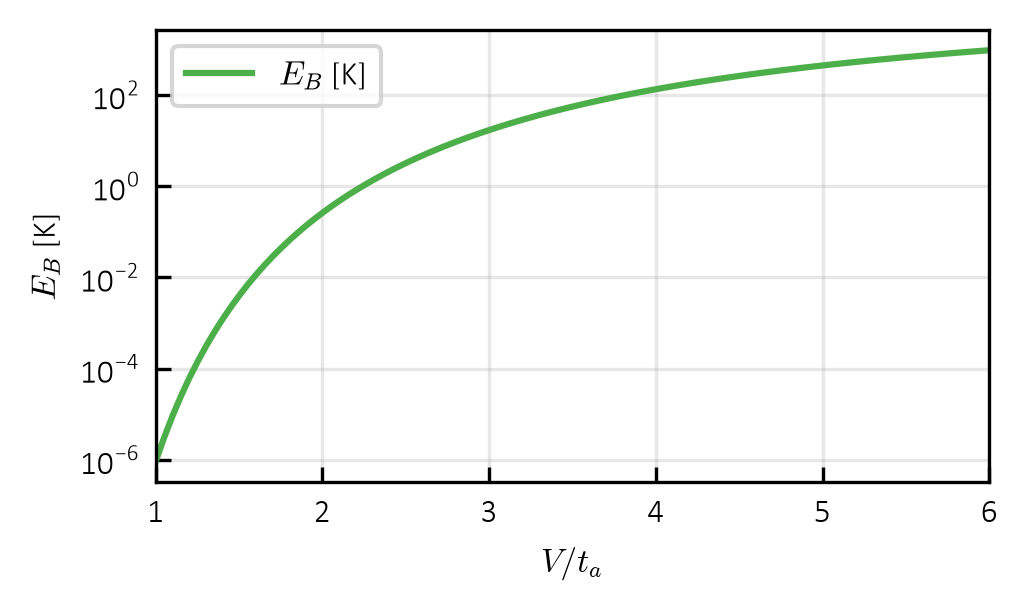

In [17]:
v_arr = np.linspace(1.0, 6.0, 100)
E_B =  []
for V in tqdm(v_arr): 
    E_B.append(e_bind(V, bp["ta"], bp["tb"]))

fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))

ax.semilogy(v_arr, np.array(E_B) * taeV / 8.617 * 10**5, color=SET1_LIST[2], label="$E_B$ [K]")
ax.set_xlim(v_arr.min(), v_arr.max())
ax.set_xlabel(r"$V/t_a$")
ax.set_ylabel(r"$E_B$ [K]")
ax.grid(alpha=0.3)
ax.legend()
ax.tick_params(which="both", direction="in")
plt.tight_layout()
# plt.savefig(FIG_PATH + "E_B_vs_V.pdf", bbox_inches="tight")

In [18]:
bc = op["bath"]
fn = getattr(pb, bc["rate"])
bq = dict(bc["pars"])
ov = bc["baths"]  # (photon, phonon)
ov

[{'kind': 'photon',
  'amp': 100000000.0,
  'dip': 0.0,
  'cs': 3945.0,
  'w0': 0.15,
  'gam': 0.005},
 {'kind': 'phonon',
  'amp': 0.001432046318,
  'dip': 0.0,
  'ta_prime': -1.0,
  'tb_prime': 1.0,
  'cs': 0.026,
  'w0': 0.0,
  'gam': 0.1}]

In [19]:
ta, tb, gg, vv_ = bp["ta"], bp["tb"], bp["gap"], p.v
kk = ta - tb  # dxi/ds, 2t for ta = -tb = t
rho = 1 / (2 * np.pi * kk)  # band bottom DOS per unit xi, 1/(4 pi t)
eb = e_bind(vv_, ta, tb)  # once per V
xb0 = 0.5 * (gg + vv_) - 2 * kk  # xi_b at m = -1
pg = next(b for b in bc["baths"] if b["kind"] == "photon")  # cavity w0, gam
logger.info(f"E_B = {eb:.5f}, 2 xi_b0 = {2 * xb0:.5f}, rho V = {rho * vv_:.4f}")

[18:53:03] [INFO    ] E_B = 0.13348, 2 xi_b0 = 0.10000, rho V = 0.3263


In [20]:
def mustar(e, jj, t1, t2):
    """Root of sum J [N1 (1 - f)^2 - (1 + N1) f^2] = 0, f = Fermi((E - mu)/T2)."""
    n1 = 1 / np.expm1(2 * e / t1)

    def bal(mu):
        lf, lh = -np.logaddexp(0, (e - mu) / t2), -np.logaddexp(0, -(e - mu) / t2)  # log f, log(1 - f)
        return np.sum(jj * (n1 * np.exp(2 * lh) - (1 + n1) * np.exp(2 * lf)))

    return brentq(bal, e.min() - 100 * max(t1, t2), e.min() + 30 * t2)


from scipy.special import expit
def closure(t1, t2, eq=False, nit=3000, tol=1e-12):
    """Band bottom mu* model, loop steps 1 to 7. eq = True: equilibrium at T2."""
    tm, tx = (t2, t2) if eq else (min(t1, t2), max(t1, t2))
    ep = np.linspace(0, min(4 * kk, 0.5 + 40 * tx), 4000)  # epsilon = xi - xi_b
    de = ep[1] - ep[0]
    hv = 2 - 0.5 * (2 - ep / kk) ** 2  # photon vertex h(s)
    dd = (eb - 2 * xb0) / (1 - rho * vv_)
    d, xb, mu = np.sqrt(max(eb * dd, 1e-12)), 0.5 * (eb - dd), 0.0
    e0, x0 = np.hypot(xb, d), xb  # T = 0 values for (305)
    for _ in range(nit):
        xi = xb + ep
        e = np.hypot(xi, d)
        if not eq:
            jj = hv * (d / (2 * e)) ** 2 * np.asarray(cv.kern(2 * e, pg["w0"], pg["gam"]))
            mu = mustar(e, jj, t1, t2)
        f = expit(-(e - mu) / t2)
        i0, i1 = np.sum(f / e) * de, rho * np.sum(xi / e * f) * de
        sm = eb * np.exp(-2 * i0)  # E_b + xi_b
        dd = (sm - 2 * xb0 + 2 * vv_ * i1) / (1 - rho * vv_)  # E_b - xi_b
        if dd <= 0:
            return dict(d=0.0, mu=mu, nqp=np.nan, lin=np.nan, dm=np.nan)
        dn, xn = np.sqrt(sm * dd), 0.5 * (sm - dd)
        if abs(dn - d) + abs(xn - xb) < tol:
            break
        d, xb = d + 0.5 * (dn - d), xb + 0.5 * (xn - xb)
    nqp = rho * np.sum(f) * de
    lin = -nqp / (rho * e0) * (1 + (eb - rho * vv_ * x0) / (eb - 2 * xb0))  # (305)
    return dict(d=d, mu=mu, nqp=nqp, lin=lin, dm=rho * dd + 2 * i1)

/tmp/ipykernel_24382/3932575484.py:3: RuntimeWarning: overflow encountered in expm1
  n1 = 1 / np.expm1(2 * e / t1)
[18:53:05] [INFO    ] closure Delta_0 = 0.08145 (lattice 0.08413)
findfont: Failed to find font weight normal, now using 300.
findfont: Failed to find font weight normal, now using 300.


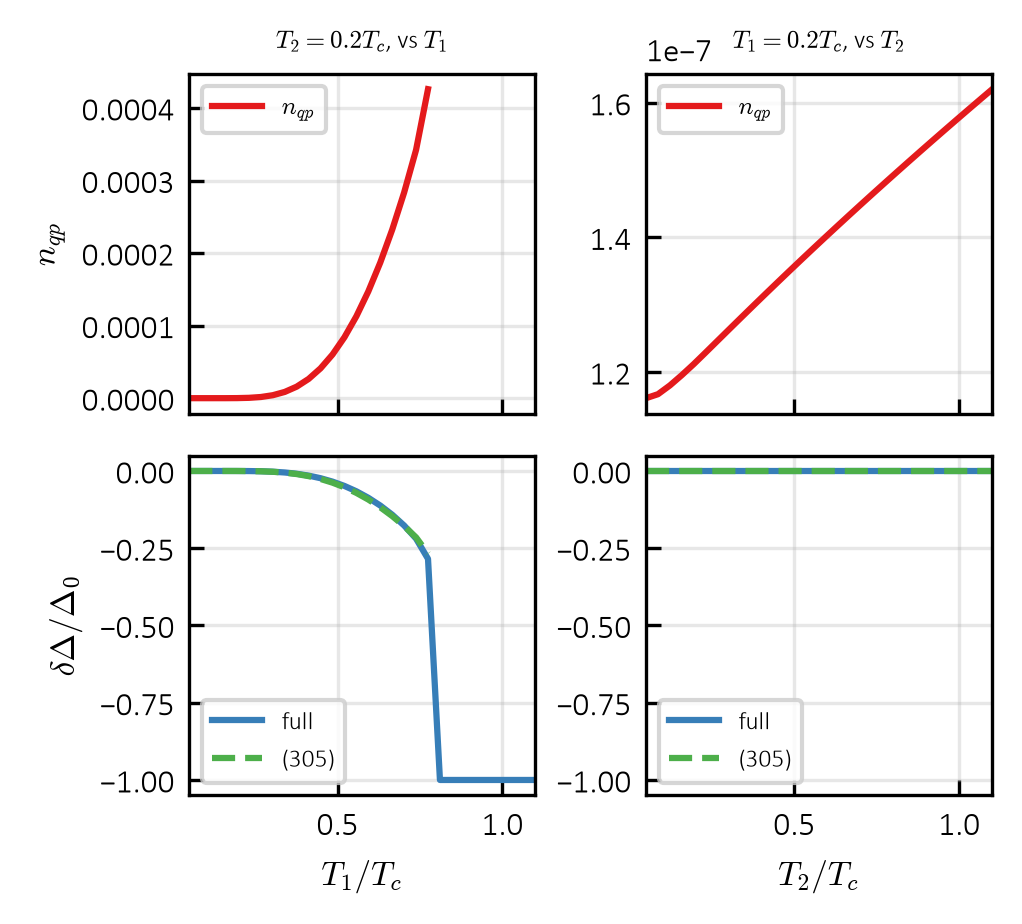

In [21]:
dc0 = closure(0, 1e-3 * tc, eq=True)["d"]  # closure Delta_0, for delta Delta / Delta_0
ts = np.linspace(0.05, 1.1, 30)
r1 = [closure(a * tc, t2) for a in ts]  # T1 scan at T2 = 0.2 Tc
r2 = [closure(t1, a * tc) for a in ts]  # T2 scan at T1 = 0.8 Tc
logger.info(f"closure Delta_0 = {dc0:.5f} (lattice {d0:.5f})")

fig, axs = plt.subplots(2, 2, sharex=True, figsize=(3.47412, 0.9 * 3.47412))
for j, (r, lb) in enumerate(((r1, rf"$T_2={t2 / tc:.1f}T_c$, vs $T_1$"), (r2, rf"$T_1={t1 / tc:.1f}T_c$, vs $T_2$"))):
    nq = np.array([x["nqp"] for x in r])
    dl = np.array([x["d"] for x in r]) / dc0 - 1
    ln = np.array([x["lin"] for x in r])
    axs[0, j].plot(ts, nq, color=SET1_LIST[0], label=r"$n_{qp}$")
    axs[1, j].plot(ts, dl, color=SET1_LIST[1], label=r"full")
    axs[1, j].plot(ts, ln, "--", color=SET1_LIST[2], label=r"(305)")
    axs[0, j].set_title(lb, fontsize=6)
axs[0, 0].set_ylabel(r"$n_{qp}$")
axs[1, 0].set_ylabel(r"$\delta\Delta/\Delta_0$")
axs[1, 0].set_xlabel(r"$T_1/T_c$")
axs[1, 1].set_xlabel(r"$T_2/T_c$")
for ax in axs.ravel():
    ax.set_xlim(ts[0], ts[-1])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=6)
    ax.tick_params(which="both", direction="in")
axs[1, 0].set_ylim(-1.05, 0.05)
axs[1, 1].set_ylim(-1.05, 0.05)
plt.tight_layout()

In [29]:
from matplotlib.colors import LogNorm

ts = np.linspace(0.05, 2.0, 51)  # T / Tc, both axes
nq = np.full((ts.size, ts.size), np.nan)  # rows T2, cols T1
dg = np.full((ts.size, ts.size), np.nan)
for j, b in enumerate(tqdm(ts)):
    for i, a in enumerate(ts):
        r = closure(a * tc, b * tc)
        nq[j, i], dg[j, i] = r["nqp"], r["d"] / dc0

  0%|          | 0/51 [00:00<?, ?it/s]

/tmp/ipykernel_24382/3932575484.py:3: RuntimeWarning: overflow encountered in expm1
  n1 = 1 / np.expm1(2 * e / t1)


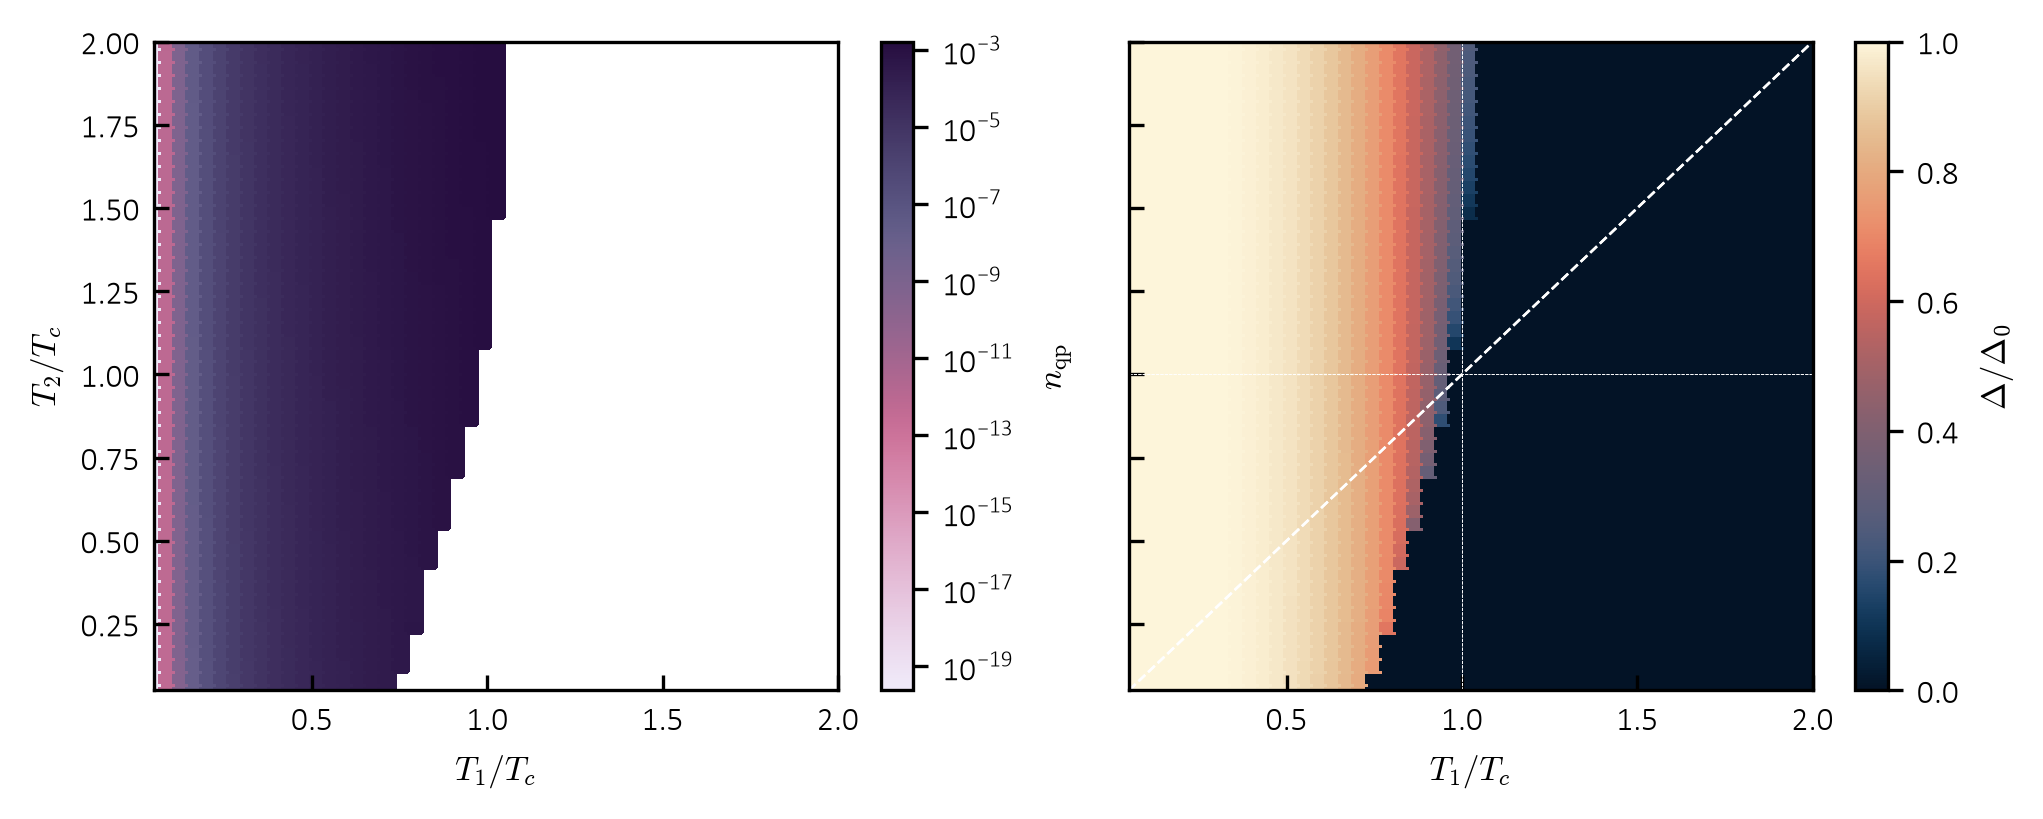

In [ ]:

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(2*3.47412, 0.8 * 3.47412))
for ax, z, lb, kw in ((axs[0], nq, r"$n_{\mathrm{qp}}$", dict(norm=LogNorm(),  cmap=cmaps.acton_r)),
                      (axs[1], dg, r"$\Delta/\Delta_0$", dict(vmin=0, vmax=1, cmap=cmaps.lipari))):
    im = ax.pcolormesh(ts, ts, z, shading="nearest", **kw)
    im.set_edgecolor("face")
    axs[1].plot(ts, ts, "w--", lw=0.6)  # T1 = T2, equilibrium
    axs[1].plot(np.ones_like(ts), ts, "w--", lw=0.2)  # T1 = T2, equilibrium
    axs[1].plot(ts, np.ones_like(ts), "w--", lw=0.2)  # T1 = T2, equilibrium
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(lb, rotation=90, labelpad=5)
    ax.set_xlabel(r"$T_1/T_c$")
    ax.set_xlim(ts[0], ts[-1])
    ax.set_ylim(ts[0], ts[-1])
    ax.tick_params(which="both", direction="in")
axs[0].set_ylabel(r"$T_2/T_c$")
plt.tight_layout()
# plt.savefig(FIG_PATH +  "gap_analytic_strongphotons.pdf", bbox_inches="tight")

Full DOS solver

In [9]:
from scipy.special import ellipk
from scipy.optimize import root

kap = np.pi * (np.arange(4000) + 0.5) / 4000
s = 2 * np.cos(kap)  # shells, dense at the band edges
w = ellipk(1 - s**2 / 4) * np.sin(kap)
w /= w.sum()  # weights g(s) ds, sum = 1
hv = 2 - 0.5 * s**2  # photon vertex h(s)


def mustar(e, jj, t1, t2):
    """Root of sum J [N1 (1 - f)^2 - (1 + N1) f^2] = 0, f = Fermi((E - mu)/T2)."""
    n1 = 1 / np.expm1(2 * e / t1)

    def bal(mu):
        lf, lh = -np.logaddexp(0, (e - mu) / t2), -np.logaddexp(0, -(e - mu) / t2)  # log f, log(1 - f)
        return np.sum(jj * (n1 * np.exp(2 * lh) - (1 + n1) * np.exp(2 * lf)))

    lo, hi = e.min() - 100 * max(t1, t2), e.min() + 30 * t2
    if not bal(lo) > 0:  # no photon coupling (u v = 0)
        return 0.0
    while bal(hi) > 0:  # strong pumping, mu* further up
        hi += 30 * t2
    return brentq(bal, lo, hi)


def gmap(t1, t2, d, m, eq=False):
    """Mean field map (d, m) -> (d', m', mu*, n_qp) on the full band."""
    xi = 0.5 * gg - kk * s - 0.5 * vv_ * m  # Hartree shifted xi(s)
    e = np.hypot(xi, d)
    u, v = np.sqrt(0.5 * (1 + xi / e)), np.sqrt(0.5 * (1 - xi / e))
    mu = 0.0 if eq else mustar(e, w * hv * (u * v) ** 2 * np.asarray(cv.kern(2 * e, pg["w0"], pg["gam"])), t1, t2)
    f = expit(-(e - mu) / t2)
    return vv_ * np.sum(w * u * v * (1 - 2 * f)), np.sum(w * (u**2 - v**2) * (2 * f - 1)), mu, np.sum(w * f)


def lattice(t1, t2, d, m, eq=False, dmin=1e-6):
    """NESS (d, m, mu*, n_qp): hybrid root on (log d, m), normal state if that fails."""
    def res(z):
        dn, mn = gmap(t1, t2, np.exp(z[0]), z[1], eq)[:2]
        return [np.log(max(dn, 1e-300)) - z[0], mn - z[1]]

    r = root(res, [np.log(max(d, 1e-3)), m], method="hybr", tol=1e-12)
    if r.success and np.exp(r.x[0]) > dmin:
        d, m = np.exp(r.x[0]), r.x[1]
        return (d, m) + gmap(t1, t2, d, m, eq)[2:]
    ml = m
    for _ in range(30):  # normal state: m at vanishing d
        _, ml, mu, nq = gmap(t1, t2, dmin, ml, eq)
    return 0.0, ml, mu, nq

In [10]:
d00, m00 = lattice(0, 1e-3 * tc, 1.0, -0.99, eq=True)[:2]  # Delta_0 of the same model
ts = np.linspace(0.05, 2.0, 25)
nq = np.full((ts.size, ts.size), np.nan)  # rows T2, cols T1
dg = np.full((ts.size, ts.size), np.nan)
for j, b in enumerate(tqdm(ts)):
    d, m = d00, m00
    for i, a in enumerate(ts):
        d, m, mu, n = lattice(a * tc, b * tc, d, m)
        nq[j, i], dg[j, i] = n, d / d00

  0%|          | 0/25 [00:00<?, ?it/s]

/tmp/ipykernel_24382/507851006.py:13: RuntimeWarning: overflow encountered in expm1
  n1 = 1 / np.expm1(2 * e / t1)
/home/kzeleznikar/IJS-F1/Koda/src/EI/ei_cavity.py:52: RuntimeWarning: overflow encountered in square
  z4 = (om**2 + gam**2) ** 2
/home/kzeleznikar/IJS-F1/Koda/src/EI/ei_cavity.py:54: RuntimeWarning: overflow encountered in square
  l = jnp.log(((om - w0) ** 2 + gam**2) * ((om + w0) ** 2 + gam**2) / w0**4)
/home/kzeleznikar/IJS-F1/Koda/src/EI/ei_cavity.py:55: RuntimeWarning: overflow encountered in square
  return (1.0 + w0**2 * (om**2 - gam**2) / z4) * a + gam * om * w0**2 / z4 * l
/home/kzeleznikar/IJS-F1/Koda/src/EI/ei_cavity.py:55: RuntimeWarning: invalid value encountered in divide
  return (1.0 + w0**2 * (om**2 - gam**2) / z4) * a + gam * om * w0**2 / z4 * l
/tmp/ipykernel_24382/507851006.py:40: RuntimeWarning: overflow encountered in exp
  dn, mn = gmap(t1, t2, np.exp(z[0]), z[1], eq)[:2]
/tmp/ipykernel_24382/507851006.py:16: RuntimeWarning: invalid value encounter

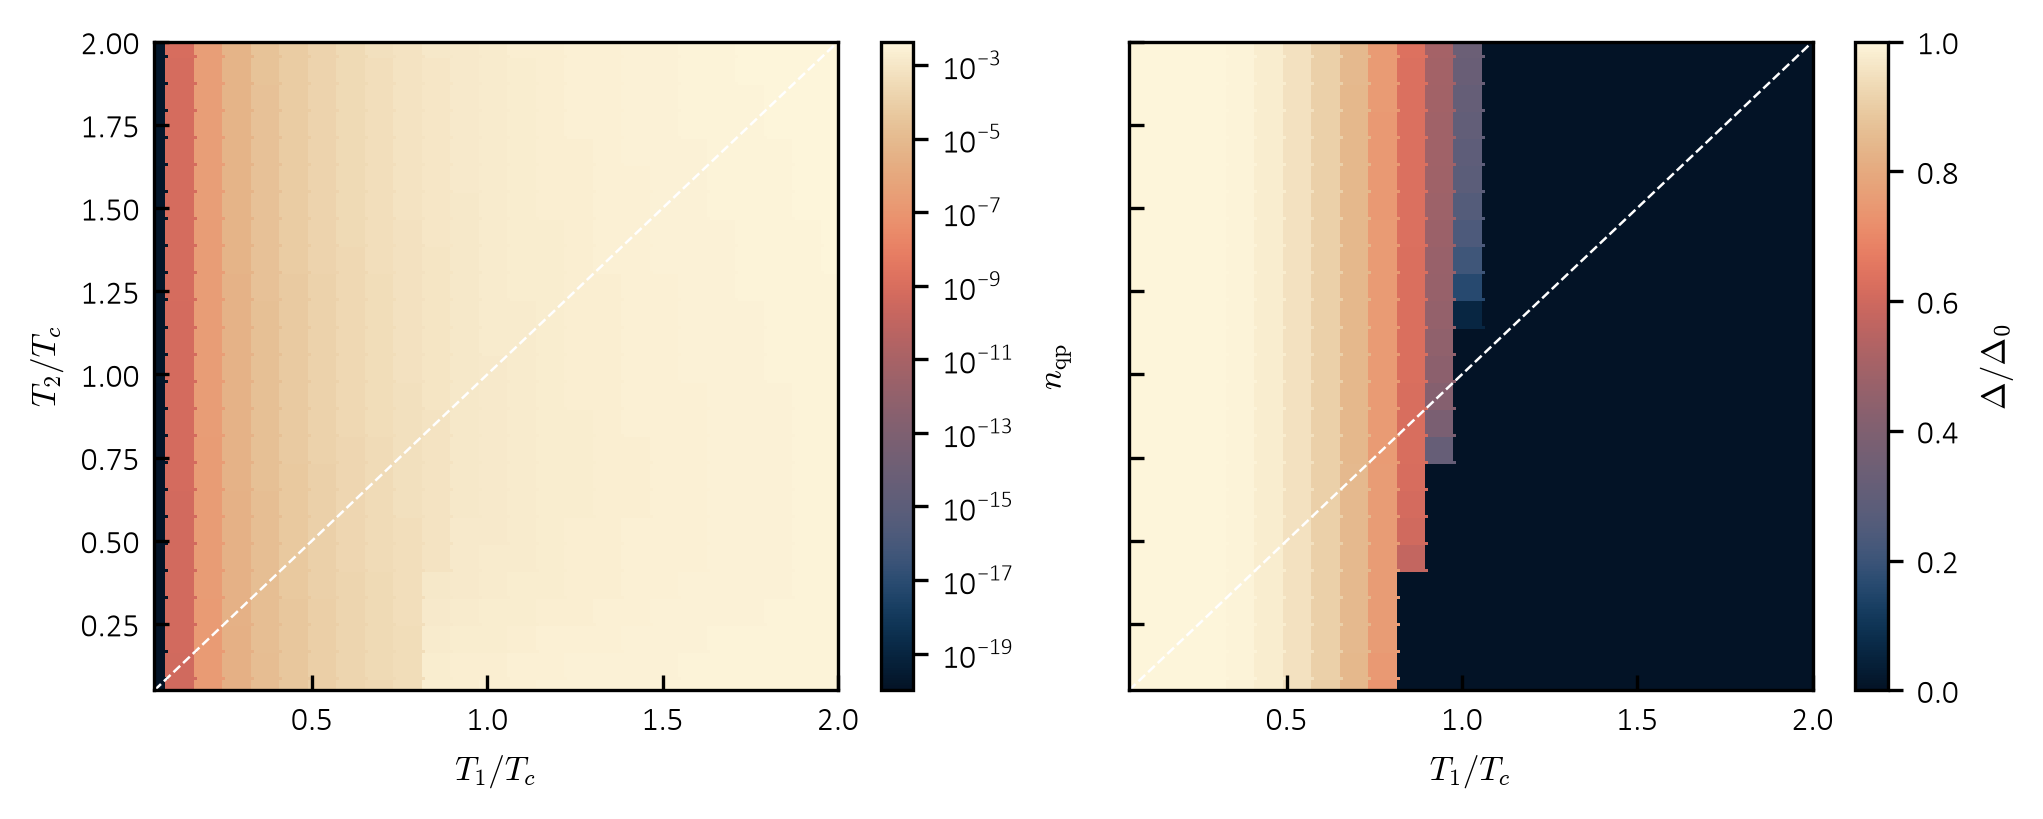

In [12]:
fig, axs = plt.subplots(1, 2, sharey=True, figsize=(2*3.47412, 0.8 * 3.47412))
for ax, z, lb, kw in ((axs[0], nq, r"$n_{\mathrm{qp}}$", dict(norm=LogNorm())),
                      (axs[1], dg, r"$\Delta/\Delta_0$", dict(vmin=0, vmax=1))):
    im = ax.pcolormesh(ts, ts, z, shading="nearest", cmap=cmaps.lipari, **kw)
    im.set_edgecolor("face")
    ax.plot(ts, ts, "w--", lw=0.6)  # T1 = T2, equilibrium
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(lb, rotation=90, labelpad=5)
    ax.set_xlabel(r"$T_1/T_c$")
    ax.set_xlim(ts[0], ts[-1])
    ax.set_ylim(ts[0], ts[-1])
    ax.tick_params(which="both", direction="in")
axs[0].set_ylabel(r"$T_2/T_c$")
plt.tight_layout()

Added phonon inertband modes. 

In [21]:
import ness_fast as nf  # only for the cached P(s, s'; q) table

pg = next(b for b in bc["baths"] if b["kind"] == "photon")  # amp, cs (= c), w0, gam
pp = next(b for b in bc["baths"] if b["kind"] == "phonon")  # amp, ta_prime, tb_prime, cs, gam

# fine shell grid: gap equations, photons, n_qp
kap = np.pi * (np.arange(4000) + 0.5) / 4000
s = 2 * np.cos(kap)  # dense at the band edges
w = ellipk(1 - s**2 / 4) * np.sin(kap)
w /= w.sum()  # g(s) ds
hv = 2 - 0.5 * s**2  # photon vertex h(s)

# coarse shell grid of the P(s, s'; q) table: phonon pair kernel
sg, qg, ptab, _ = nf.geometry(path="geo_ufree.npz")  # built once, cached
ptab = np.asarray(ptab, float)
kc = np.pi * (np.arange(sg.size) + 0.5) / sg.size
wc = ellipk(1 - sg**2 / 4) * np.sin(kc)
wc /= wc.sum()  # g(s) ds on the coarse nodes
wq = np.full(qg.size, qg[1])
wq[[0, -1]] *= 0.5  # trapezoid weights in q

In [22]:
print(pg)
print(pp)

{'kind': 'photon', 'amp': 1.0, 'dip': 0.0, 'cs': 3945.0, 'w0': 0.15, 'gam': 0.005}
{'kind': 'phonon', 'amp': 1.432046318e-07, 'dip': 0.0, 'ta_prime': -1.0, 'tb_prime': 1.0, 'cs': 0.026, 'w0': 0.0, 'gam': 0.1}


In [23]:
def bands(s_, d, m):
    """xi, E, u, v on shells s_."""
    xi = 0.5 * gg - kk * s_ - 0.5 * vv_ * m
    e = np.hypot(xi, d)
    return xi, e, np.sqrt(0.5 * (1 + xi / e)), np.sqrt(0.5 * (1 - xi / e))


def jph(e, u, v):
    """Photon pair weights J(s) g ds, step 2."""
    return (pg["amp"] / (2 * np.pi * pg["cs"] ** 2) * hv * (2 * kk * u * v) ** 2
            * np.asarray(cv.kern(2 * e, pg["w0"], pg["gam"])) * w)


def wph(d, m, t2):
    """Phonon pair kernel W N2 g g' ds ds' on the active coarse nodes, step 3."""
    _, e, u, v = bands(sg, d, m)
    k = np.flatnonzero(np.isfinite(e) & (e <= np.nanmin(e) + 40 * t2 + 0.2))
    if k.size == 0:  # nonfinite trial point of the root finder: no phonon pair channel
        return np.zeros(1), np.zeros((1, 1))
    om = e[k, None] + e[None, k]  # pair energy E + E'
    lz = lambda z: pp["gam"] / np.pi / (z**2 + pp["gam"] ** 2)
    dg = (lz(om[..., None] - pp["cs"] * qg) - lz(om[..., None] + pp["cs"] * qg)) * wq / pp["cs"]
    geo = np.einsum("ijl,ijl->ij", ptab[np.ix_(k, k)], dg)  # int dq P delta_gamma / cs
    m2 = (2 * (pp["ta_prime"] * u[k, None] * v[None, k] - pp["tb_prime"] * v[k, None] * u[None, k])) ** 2
    return e[k], pp["amp"] * m2 * geo / np.expm1(om / t2) * wc[k, None] * wc[None, k]

def lexpm1(x):
    """log |e^x - 1|, no overflow."""
    return np.where(x > 0, x + np.log1p(-np.exp(-np.abs(x))), np.log(-np.expm1(-np.abs(x))))


def mustar(e, jj, ec, w2, t1, t2):
    """Photon balance + (1 - e^{2 mu/T2}) phonon pair weight = 0, phonon term in logs."""
    n1 = 1 / np.expm1(2 * e / t1)
    lw2 = np.log(np.maximum(w2, 1e-300))

    def bal(mu):
        lf, lh = -np.logaddexp(0, (e - mu) / t2), -np.logaddexp(0, -(e - mu) / t2)  # log f, log(1 - f)
        gp = np.sum(jj * (n1 * np.exp(2 * lh) - (1 + n1) * np.exp(2 * lf)))  # photons
        lc = -np.logaddexp(0, -(ec - mu) / t2)  # log(1 - f) on the coarse nodes
        z = lw2 + lc[:, None] + lc[None, :]
        zm = z.max()
        if not np.isfinite(zm):  # no phonon pair weight
            return gp
        lph = lexpm1(2 * mu / t2) + zm + np.log(np.sum(np.exp(z - zm)))
        return gp - np.sign(mu) * np.exp(lph)  # phonons pull mu* to 0

    lo, hi = e.min() - 100 * max(t1, t2), e.min() + 30 * t2
    if not bal(lo) > 0:  # no pair coupling
        return 0.0
    while bal(hi) > 0:
        hi += 30 * t2
    return brentq(bal, lo, hi)

def gmap(t1, t2, d, m):
    """Steps 1 to 6: (d, m) -> (d', m', mu*, n_qp)."""
    _, e, u, v = bands(s, d, m)
    ec, w2 = wph(d, m, t2)
    mu = mustar(e, jph(e, u, v), ec, w2, t1, t2)
    f = expit(-(e - mu) / t2)
    return vv_ * np.sum(w * u * v * (1 - 2 * f)), np.sum(w * (u**2 - v**2) * (2 * f - 1)), mu, np.sum(w * f)


def lattice2(t1, t2, d, m, dmin=1e-6):
    """NESS (d, m, mu*, n_qp): hybrid root on (log d, m), step 7 if it fails."""
    def res(z):
        zc = np.clip(z, [np.log(1e-9), -1.0], [np.log(10.0), 1.0])  # evaluate only at physical trial points
        dn, mn = gmap(t1, t2, np.exp(zc[0]), zc[1])[:2]
        return [np.log(max(dn, 1e-300)) - z[0], mn - z[1]]
    
    r = root(res, [np.log(max(d, 1e-3)), m], method="hybr", tol=1e-12)
    if r.success and np.exp(r.x[0]) > dmin:
        d, m = np.exp(r.x[0]), r.x[1]
        return (d, m) + gmap(t1, t2, d, m)[2:]
    ml = m
    for _ in range(30):  # normal state: m at vanishing d
        _, ml, mu, nq = gmap(t1, t2, dmin, ml)
    return 0.0, ml, mu, nq

  0%|          | 0/25 [00:00<?, ?it/s]

/tmp/ipykernel_42375/1610542161.py:34: RuntimeWarning: overflow encountered in expm1
  n1 = 1 / np.expm1(2 * e / t1)
/tmp/ipykernel_42375/1610542161.py:25: RuntimeWarning: overflow encountered in expm1
  return e[k], pp["amp"] * m2 * geo / np.expm1(om / t2) * wc[k, None] * wc[None, k]
/tmp/ipykernel_42375/1610542161.py:46: RuntimeWarning: overflow encountered in exp
  return gp - np.sign(mu) * np.exp(lph)  # phonons pull mu* to 0
/tmp/ipykernel_42375/1610542161.py:29: RuntimeWarning: divide by zero encountered in log1p
  return np.where(x > 0, x + np.log1p(-np.exp(-np.abs(x))), np.log(-np.expm1(-np.abs(x))))


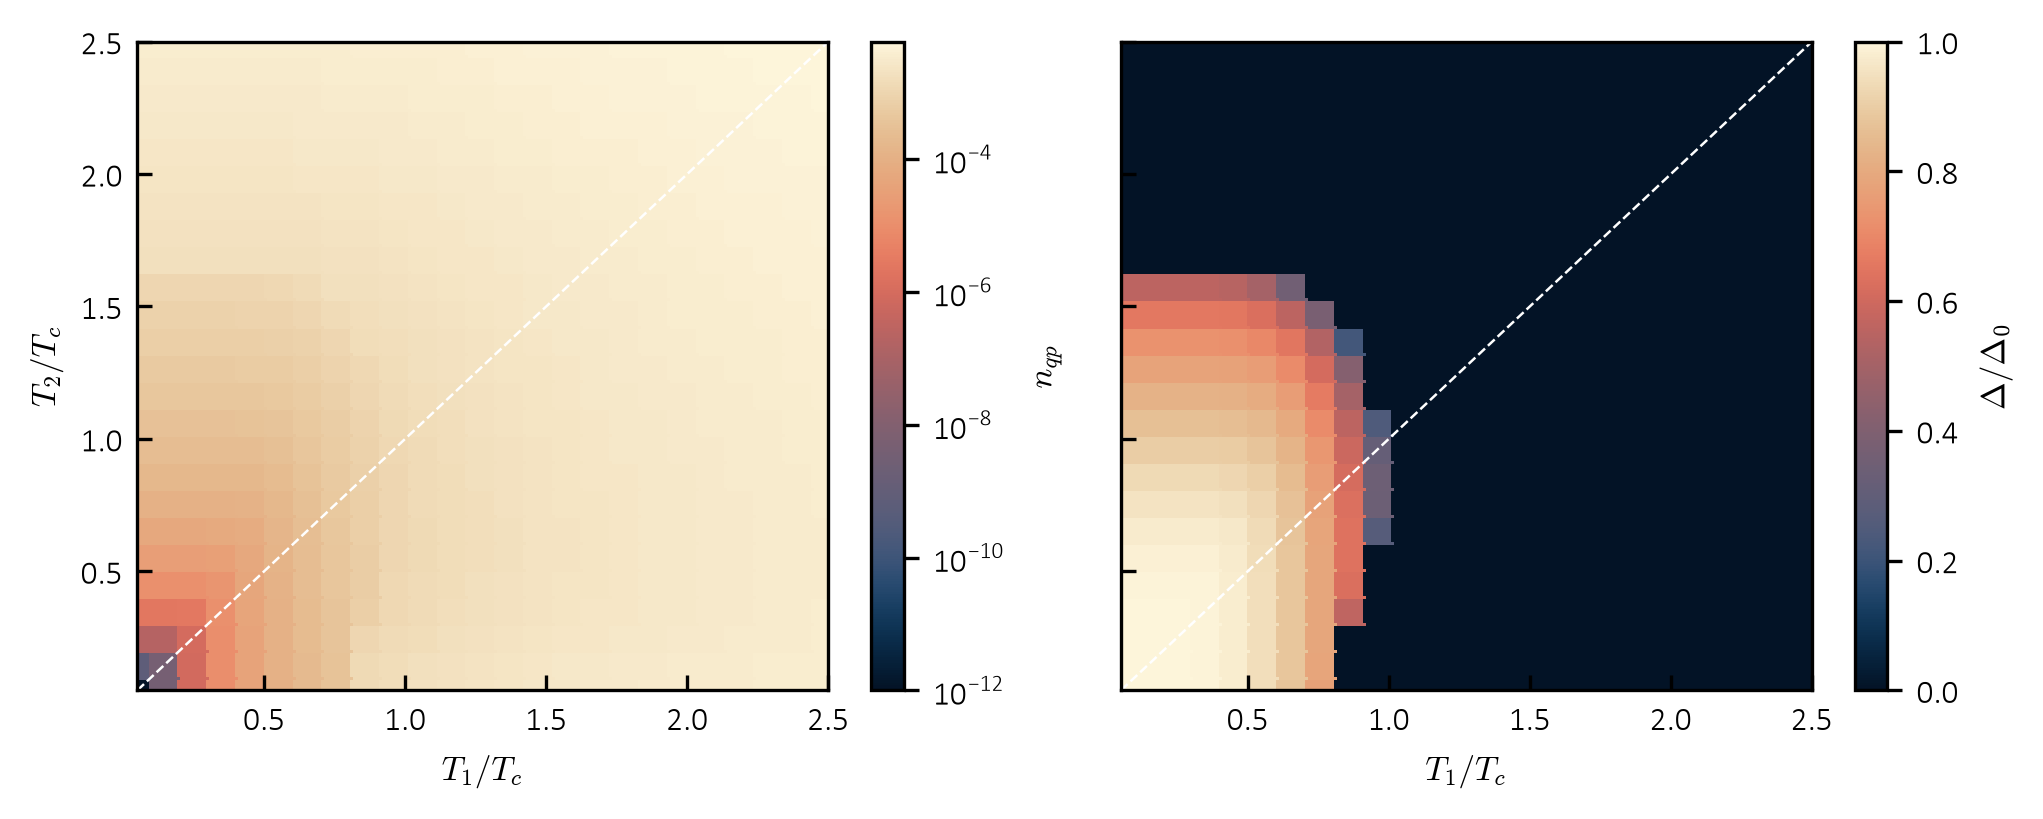

In [24]:
from matplotlib.colors import LogNorm

d00, m00 = d0, m0  # T = 0 lattice gap and m as the reference and the start
ts = np.linspace(0.05, 2.5, 25)
nq = np.full((ts.size, ts.size), np.nan)  # rows T2, cols T1
dg = np.full((ts.size, ts.size), np.nan)
for j, b in enumerate(tqdm(ts)):
    d, m = d00, m00
    for i, a in enumerate(ts):
        d, m, mu, n = lattice2(a * tc, b * tc, d, m)  # warm start along the row
        nq[j, i], dg[j, i] = n, d / d00

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(2 * 3.47412, 0.8 * 3.47412))
for ax, z, lb, kw in ((axs[0], nq, r"$n_{qp}$", dict(norm=LogNorm(vmin=1e-12))),
                      (axs[1], dg, r"$\Delta/\Delta_0$", dict(vmin=0, vmax=1))):
    im = ax.pcolormesh(ts, ts, z, shading="nearest", cmap=cmaps.lipari, **kw)
    im.set_edgecolor("face")
    ax.plot(ts, ts, "w--", lw=0.6)  # T1 = T2, equilibrium
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(lb, rotation=90, labelpad=5)
    ax.set_xlabel(r"$T_1/T_c$")
    ax.set_xlim(ts[0], ts[-1])
    ax.set_ylim(ts[0], ts[-1])
    ax.tick_params(which="both", direction="in")
axs[0].set_ylabel(r"$T_2/T_c$")
plt.tight_layout()